<a href="https://colab.research.google.com/github/Dalton115/MAT-422/blob/main/HW3_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW3.2    3.2.1 - 3.2.3

* Used Gemini as a study aid and coding partner to clarify multivariate calculus definitions, debug python code, and format LaTex formulas.
__________________________________________________________________

1. Limits and Continuity (3.2.1)
2. Derivatives (3.2.2)
3. Taylor's Theorem (3.2.3)

__________________________________________________________________

# Limits and Continuity (3.2.1)

Key Concepts (Explained and given python example)

* Limits are a math notation to show the behavior of a graph as it approaches a limit. (like infinity or negative infinity)

$\lim_{x \to a} f(x) = L$ means for every $\epsilon > 0$, there exists $\delta > 0$ such that $\vert{}f(x) - L\vert{} < \epsilon$ whenever $x \in D \cap B_\delta(a) \setminus \{a\}$

* Continuity says: $f$ is continuous at $a \in D$ if $\lim_{x \to a} f(x) = f(a)$

* Composition: If $f: D_1 \to \mathbb{R}^m$ is continuous at $x_0$ and $g: D_2 \to \mathbb{R}^p$ is continuous at $f(x_0)$, then $(g \circ f)(x) = g(f(x))$ is continuous at $x_0$.

* Extreme Value Theorem (EVT): If $f: D \to \mathbb{R}$ is continuous on a nonempty, closed, and bounded (compact) domain $D \subseteq \mathbb{R}^d$, then $f$ attains a global maximum and a global minimum on $D$.

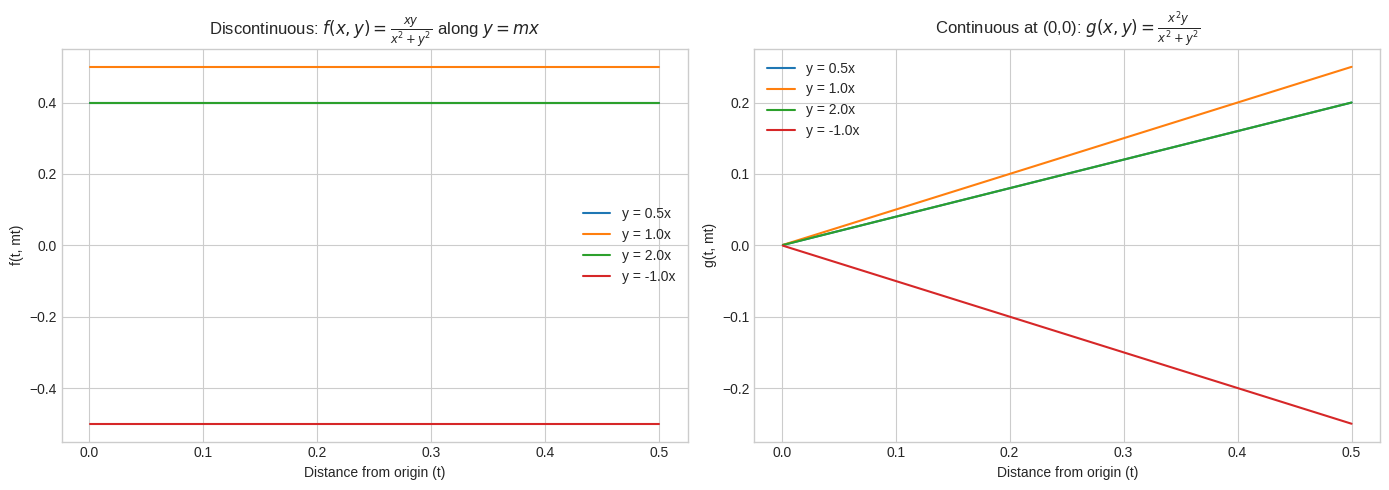

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Notebook styling parameters
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig_size = (10, 6)

 # Create grid approaching origin
x = np.linspace(-1, 1, 400)
y = np.linspace(-1, 1, 400)
X, Y = np.meshgrid(x, y)

# Define functions (handling 0/0 at origin)
with np.errstate(divide='ignore', invalid='ignore'):
    F = (X * Y) / (X**2 + Y**2)
    G = (X**2 * Y) / (X**2 + Y**2)
    F[X**2 + Y**2 == 0] = np.nan
    G[X**2 + Y**2 == 0] = 0.0

# Numerical verification along lines y = m * x
slopes = [0.5, 1.0, 2.0, -1.0]
t = np.linspace(0.001, 0.5, 100)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot f(x,y) along paths
for m in slopes:
    path_val_f = (t * (m * t)) / (t**2 + (m * t)**2)
    axes[0].plot(t, path_val_f, label=f'y = {m}x')

axes[0].set_title(r'Discontinuous: $f(x,y) = \frac{xy}{x^2+y^2}$ along $y=mx$')
axes[0].set_xlabel('Distance from origin (t)')
axes[0].set_ylabel('f(t, mt)')
axes[0].legend()

# Plot g(x,y) along paths
for m in slopes:
    path_val_g = (t**2 * (m * t)) / (t**2 + (m * t)**2)
    axes[1].plot(t, path_val_g, label=f'y = {m}x')

axes[1].set_title(r'Continuous at (0,0): $g(x,y) = \frac{x^2y}{x^2+y^2}$')
axes[1].set_xlabel('Distance from origin (t)')
axes[1].set_ylabel('g(t, mt)')
axes[1].legend()

plt.tight_layout()
plt.show()

In calculus, a limit only exists if f(x) approaches the same value L along every path approaching a.
* The example on the left that as t approaches 0, each line levels off at a different value based on its slope. since the limit depends on the path taken, the limit does not exist. It is discontinuous.
* Regardless of the slope, each path converges to the same place as t approaches 0. Its limit exists and it's continuous.

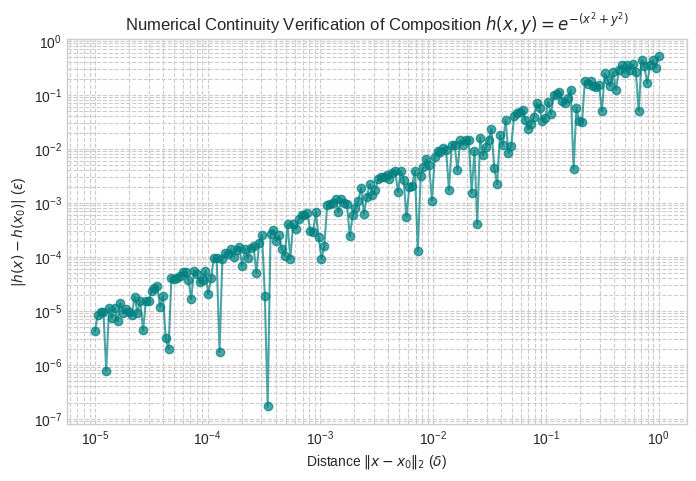

In [ ]:
# Center point x0
x0 = np.array([0.5, 0.5])

# Continuous functions
def f(x):
    return np.sum(x**2, axis=-1)

def g(u):
    return np.exp(-u)

def h(x):
    return g(f(x))

# Evaluate at x0
h_x0 = h(x0)

# Generate points approaching x0 in random directions
np.random.seed(42)
num_samples = 200
deltas = np.logspace(-5, 0, num_samples)
errors = []

for d in deltas:
    direction = np.random.randn(2)
    direction /= np.linalg.norm(direction)
    x_near = x0 + d * direction
    errors.append(abs(h(x_near) - h_x0))

plt.figure(figsize=(8, 5))
plt.loglog(deltas, errors, 'o-', alpha=0.7, color='teal')
plt.xlabel(r'Distance $\|x - x_0\|_2$ ($\delta$)')
plt.ylabel(r'$|h(x) - h(x_0)|$ ($\epsilon$)')
plt.title(r'Numerical Continuity Verification of Composition $h(x,y) = e^{-(x^2+y^2)}$')
plt.grid(True, which="both", ls="--")
plt.show()

The output errors shrinks as we move right to left proportionate to input distance. The shrinking error verifies composing multiple continuous functions yields a continuous result.

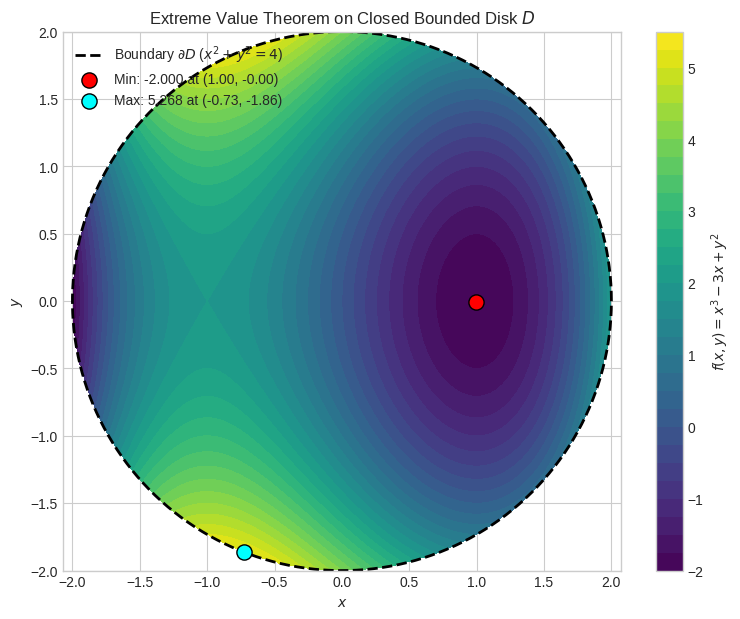

Verified Global Minimum on D: f0.9980, -0.0040 = -2.0000
Verified Global Maximum on D: f-0.7255, -1.8637 = 5.2680


In [ ]:
# Define domain D: disk of radius R = 2
R = 2.0
resolution = 500
x_grid = np.linspace(-R, R, resolution)
y_grid = np.linspace(-R, R, resolution)
X, Y = np.meshgrid(x_grid, y_grid)

# Mask for closed bounded domain D
mask = (X**2 + Y**2) <= R**2

# Continuous function values
Z = X**3 - 3*X + Y**2
Z_domain = np.where(mask, Z, np.nan)

# Numerical search for min and max on D
min_val = np.nanmin(Z_domain)
max_val = np.nanmax(Z_domain)

min_idx = np.unravel_index(np.nanargmin(Z_domain), Z_domain.shape)
max_idx = np.unravel_index(np.nanargmax(Z_domain), Z_domain.shape)

min_point = (X[min_idx], Y[min_idx])
max_point = (X[max_idx], Y[max_idx])

# Plot contour map with extrema
plt.figure(figsize=(9, 7))
contour = plt.contourf(X, Y, Z_domain, levels=30, cmap='viridis')
plt.colorbar(contour, label=r'$f(x,y) = x^3 - 3x + y^2$')

# Plot domain boundary
theta = np.linspace(0, 2*np.pi, 200)
plt.plot(R*np.cos(theta), R*np.sin(theta), 'k--', linewidth=2, label=r'Boundary $\partial D$ ($x^2+y^2=4$)')

# Highlight Extrema
plt.scatter(*min_point, color='red', s=120, edgecolors='black', zorder=5,
            label=f'Min: {min_val:.3f} at ({min_point[0]:.2f}, {min_point[1]:.2f})')
plt.scatter(*max_point, color='cyan', s=120, edgecolors='black', zorder=5,
            label=f'Max: {max_val:.3f} at ({max_point[0]:.2f}, {max_point[1]:.2f})')

plt.title('Extreme Value Theorem on Closed Bounded Disk $D$')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend(loc='upper left')
plt.axis('equal')
plt.show()

print(f"Verified Global Minimum on D: f{min_point[0]:.4f}, {min_point[1]:.4f} = {min_val:.4f}")
print(f"Verified Global Maximum on D: f{max_point[0]:.4f}, {max_point[1]:.4f} = {max_val:.4f}")

The EVT states that if a function is continuous for a closed and bounded set, it has a global max and minimum. The contour plot shows larger values with lighter green color, and lower values with darker purple color. The plot demonstrates the guaranteed global min and max.

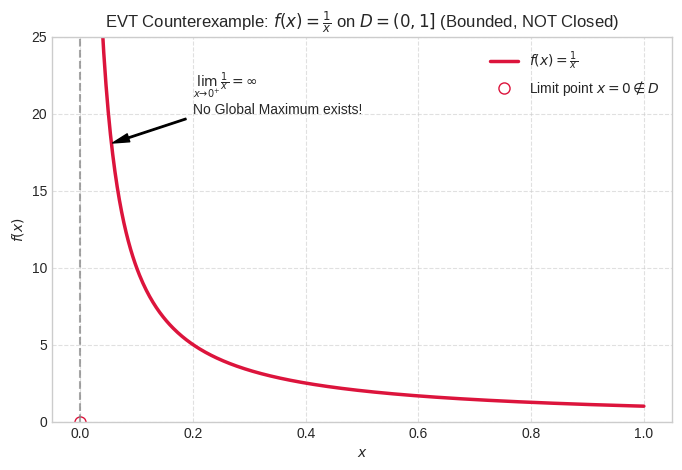

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Domain: (0, 1] - Bounded, but NOT closed (0 is missing)
x = np.linspace(0.01, 1.0, 500)
f_x = 1 / x

plt.figure(figsize=(8, 5))
plt.plot(x, f_x, color='crimson', linewidth=2.5, label=r'$f(x) = \frac{1}{x}$')

# Highlight open boundary at x = 0
plt.plot(0, 0, 'o', markerfacecolor='white', markeredgecolor='crimson',
         markersize=8, label=r'Limit point $x=0 \notin D$')

plt.axvline(x=0, color='gray', linestyle='--', alpha=0.7)
plt.ylim(0, 25)
plt.xlim(-0.05, 1.05)

plt.title(r'EVT Counterexample: $f(x) = \frac{1}{x}$ on $D = (0, 1]$ (Bounded, NOT Closed)', fontsize=12)
plt.xlabel('$x$')
plt.ylabel('$f(x)$')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.annotate(r'$\lim_{x \to 0^+} \frac{1}{x} = \infty$' + '\nNo Global Maximum exists!',
             xy=(0.05, 18), xytext=(0.2, 20),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

plt.show()

Here is a simple example with 1/x where D is continuous and bounded, but not closed. Since it's open at x = 0, there is actually no global maximum. Giving an example why the EVT requires a closed domain.

# Derivatives (3.2.2)

Key Concepts (Explained and given python example)

* A derivative measures the rate of change of a certain function:

$f'(x_0) = \lim_{h \to 0} \frac{f(x_0 + h) - f(x_0)}{h}$. Measures the instantaneous rate of change.

* Linearity: Differentiation is a linear operator: $[\alpha f(x) + \beta g(x)]' = \alpha f'(x) + \beta g'(x)$.

* Rolle's Theorem: If $f \in C[a, b]$ is differentiable on $(a, b)$ and $f(a) = f(b)$, there exists at least one $c \in (a, b)$ where $f'(c) = 0$.
* Mean Value Theorem (MVT):
If $f \in C[a, b]$ is differentiable on $(a, b)$, there exists $c \in (a, b)$ such that the instantaneous rate equals the average rate:$$f'(c) = \frac{f(b) - f(a)}{b - a}$$
* Partial Derivatives: Rate of change along a standard basis vector $e_i$: $\frac{\partial f(x_0)}{\partial x_i} = \lim_{h \to 0} \frac{f(x_0 + h e_i) - f(x_0)}{h}$
* Jacobian Matrix: For vector functions $f: \mathbb{R}^d \to \mathbb{R}^m$, $J_f(x_0) \in \mathbb{R}^{m \times d}$ consists of all first-order partial derivatives:$$(J_f)_{ij} = \frac{\partial f_i}{\partial x_j}$$

* Gradient:
For scalar functions $f: \mathbb{R}^d \to \mathbb{R}$, $J_f(x_0) = \nabla f(x_0)^T$, where $\nabla f(x_0) \in \mathbb{R}^d$.


Affine Form: $\nabla (q^T x + r) = q$

Quadratic Form: $\nabla \left(\frac{1}{2} x^T P x + q^T x + r\right) = \frac{1}{2}(P + P^T)x + q$

* Multivariate Chain Rule: For $h = g \circ f$, $J_{g \circ f}(x_0) = J_g(f(x_0)) J_f(x_0)$.

* Directional Derivative: For a unit vector $v \in \mathbb{R}^d$, the rate of change in direction $v$ is:$$\frac{\partial f(x_0)}{\partial v} = \nabla f(x_0)^T v$$
* Hessian Matrix: Matrix of second-order partial derivatives $H_f(x_0) \in \mathbb{R}^{d \times d}$, defined as $(H_f)_{ij} = \frac{\partial^2 f}{\partial x_i \partial x_j}$.
* Symmetry: If $f$ is twice continuously differentiable ($C^2$), then $H_f(x_0) = H_f(x_0)^T$ (i.e., $\frac{\partial^2 f}{\partial x_i \partial x_j} = \frac{\partial^2 f}{\partial x_j \partial x_i}$).

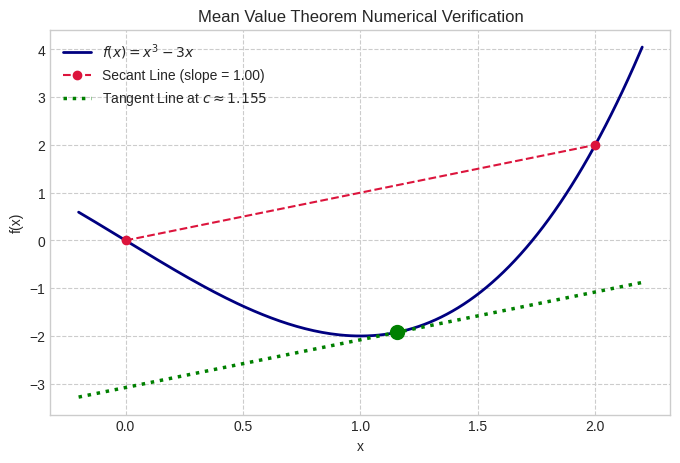

Secant Slope: 1.0000
Derivative at c=1.1547: 1.0000


In [ ]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Function and its derivative
def f(x):
    return x**3 - 3*x

def df(x):
    return 3*x**2 - 3

a, b = 0.0, 2.0
secant_slope = (f(b) - f(a)) / (b - a)

# Solve f'(c) = secant_slope => 3*c^2 - 3 = 1 => c = sqrt(4/3)
c = np.sqrt((secant_slope + 3) / 3)

# Plotting MVT
x_vals = np.linspace(-0.2, 2.2, 200)
plt.figure(figsize=(8, 5))
plt.plot(x_vals, f(x_vals), label=r'$f(x) = x^3 - 3x$', color='navy', lw=2)

# Secant Line
plt.plot([a, b], [f(a), f(b)], 'o--', color='crimson', label=f'Secant Line (slope = {secant_slope:.2f})')

# Tangent Line at c
tangent_y = f(c) + secant_slope * (x_vals - c)
plt.plot(x_vals, tangent_y, ':', color='green', lw=2.5, label=f'Tangent Line at $c \\approx {c:.3f}$')
plt.scatter([c], [f(c)], color='green', s=100, zorder=5)

plt.title('Mean Value Theorem Numerical Verification')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True, linestyle='--')
plt.show()

print(f"Secant Slope: {secant_slope:.4f}")
print(f"Derivative at c={c:.4f}: {df(c):.4f}")

Here we verify the MVT for a certain function on the interval $[a, b] = [0, 2]$. You can see from the graph clearly the tangent line is parallel to the secant line between a and b.

In [ ]:
# Define symbolic variables
x1, x2 = sp.symbols('x1 x2')
x = sp.Matrix([x1, x2])

# Matrix parameters
P = sp.Matrix([[2, 1],
               [3, 4]]) # Asymmetric matrix P
q = sp.Matrix([1, -2])
r = 5

# Quadratic Function: f(x) = 1/2 * x^T P x + q^T x + r
f_x = (sp.Rational(1, 2) * (x.T * P * x)[0] + (q.T * x)[0] + r)

# Analytical Gradient computation via SymPy
grad_f_symbolic = sp.Matrix([sp.diff(f_x, var) for var in x])

# Formula Gradient: 1/2 * (P + P^T) x + q
grad_f_formula = sp.Rational(1, 2) * (P + P.T) * x + q

print("Gradient equivalence check:", grad_f_symbolic == grad_f_formula)

# --- Chain Rule Verification ---
# Let f(x): R^2 -> R^2 where f(x) = [x1^2 + x2, x1 * x2]
# Let g(u): R^2 -> R where g(u) = u1^2 + u2^2
f_vec = sp.Matrix([x1**2 + x2, x1 * x2])
u1, u2 = sp.symbols('u1 u2')
g_scalar = u1**2 + u2**2

# Composite function: h(x) = g(f(x))
h_x = g_scalar.subs({u1: f_vec[0], u2: f_vec[1]})

# Evaluate at x0 = (1, 2)
x0_dict = {x1: 1, x2: 2}
x0_val = sp.Matrix([1, 2])

# Direct Jacobian of h
J_h_direct = sp.Matrix([[sp.diff(h_x, x1), sp.diff(h_x, x2)]]).subs(x0_dict)

# Chain Rule: J_g(f(x0)) * J_f(x0)
J_f = f_vec.jacobian(x)
J_f_x0 = J_f.subs(x0_dict)

f_x0 = f_vec.subs(x0_dict)
J_g = sp.Matrix([[sp.diff(g_scalar, u1), sp.diff(g_scalar, u2)]])
J_g_fx0 = J_g.subs({u1: f_x0[0], u2: f_x0[1]})

J_h_chain = J_g_fx0 * J_f_x0

print("Direct Composite Jacobian J_h(x0):", J_h_direct)
print("Chain Rule Product J_g(f(x0)) * J_f(x0):", J_h_chain)
print("Chain Rule Verified:", J_h_direct == J_h_chain)

Gradient equivalence check: True
Direct Composite Jacobian J_h(x0): Matrix([[20, 10]])
Chain Rule Product J_g(f(x0)) * J_f(x0): Matrix([[20, 10]])
Chain Rule Verified: True


Above we verify the vector derivatives of a quadratic form $f(x) = \frac{1}{2} x^T P x + q^T x + r$ and the multivariate chain rule using sympy.

In [ ]:
x, y = sp.symbols('x y')
f = x**3 * y**2 - sp.sin(x * y)

# Point of evaluation x0
x0 = {x: 1.0, y: 2.0}

# 1. Directional Derivative along unit vector v
v_raw = np.array([3.0, 4.0])
v = v_raw / np.linalg.norm(v_raw) # Normalize to unit vector

grad_f = sp.Matrix([sp.diff(f, x), sp.diff(f, y)])
grad_f_evaluated = np.array([float(grad_f[0].subs(x0)), float(grad_f[1].subs(x0))])

directional_deriv = np.dot(grad_f_evaluated, v)

# 2. Hessian Matrix and Symmetry Check
H_f = sp.Matrix([
    [sp.diff(f, x, x), sp.diff(f, x, y)],
    [sp.diff(f, y, x), sp.diff(f, y, y)]
])

H_eval = np.array(H_f.subs(x0)).astype(np.float64)

print(f"Gradient at (1, 2): {grad_f_evaluated}")
print(f"Directional Derivative in direction {v}: {directional_deriv:.5f}")
print("\nHessian Matrix H_f at (1, 2):\n", H_eval)
print("Is Hessian Symmetric (H == H^T)?", np.allclose(H_eval, H_eval.T))

Gradient at (1, 2): [12.83229367  4.41614684]
Directional Derivative in direction [0.6 0.8]: 11.23229

Hessian Matrix H_f at (1, 2):
 [[27.63718971 14.23474169]
 [14.23474169  2.90929743]]
Is Hessian Symmetric (H == H^T)? True


Here we demonstrate the Hessian Matrix and Directional Derivatives. By evaluating the directional derivative $\nabla f(x_0)^T v$ of $f(x, y) = x^3 y^2 - \sin(xy)$ along unit vector $v$, and verify that $H_f = H_f^T$.

# Taylor's Theorem

Key Concepts (Explained and given python example)

* 1D Taylor Expansion: Approximates an $m$-times continuously differentiable function $f$ near $a$:$$f(b) = \sum_{k=0}^{m-1} \frac{(b-a)^k}{k!} f^{(k)}(a) + R_m$$
* Second Order Special Case (m=2):

$$f(b) = f(a) + (b-a)f'(a) + \frac{1}{2}(b-a)^2 f''(\xi) \quad \text{for some } \xi \in (a, b)$$

Multivariate MVT: For $p = x - x_0$, if $f$ is continuously differentiable on an open ball containing $x$, there exists $\xi \in (0, 1)$ such that:$$f(x) = f(x_0) + \nabla f(x_0 + \xi p)^T p$$

Second Order Expansion with Remainder:
Asymptotic Form ($C^3$ functions):$$f(x) = f(x_0) + \nabla f(x_0)^T p + \frac{1}{2} p^T H_f(x_0) p + O(\Vert{}p\Vert{}^3)$$Exact Mean Value Form ($C^2$ functions):$$f(x) = f(x_0) + \nabla f(x_0)^T p + \frac{1}{2} p^T H_f(x_0 + \xi p) p \quad \text{for some } \xi \in (0, 1)$$

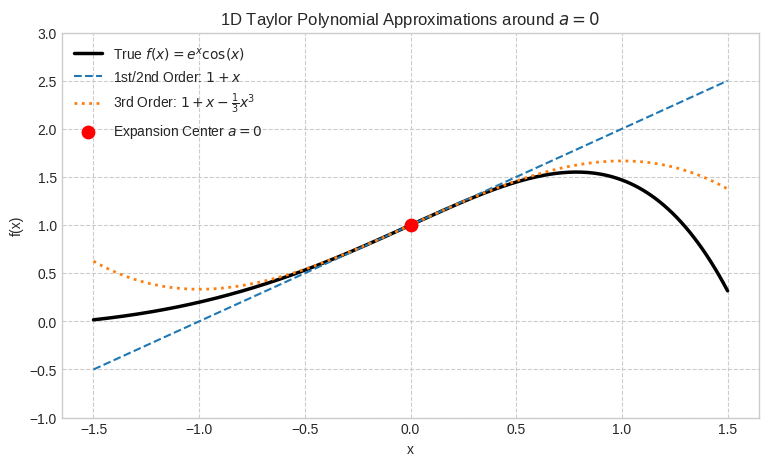

In [ ]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

def f_1d(x):
    return np.exp(x) * np.cos(x)

# Derivatives at a = 0
# f(0) = 1
# f'(x) = e^x(cos x - sin x) => f'(0) = 1
# f''(x) = -2 e^x sin x => f''(0) = 0
# f'''(x) = -2 e^x(sin x + cos x) => f'''(0) = -2

a = 0.0
x_range = np.linspace(-1.5, 1.5, 300)

P0 = np.ones_like(x_range)                          # 0th order: 1
P1 = 1 + x_range                                    # 1st order: 1 + x
P2 = 1 + x_range                                    # 2nd order: 1 + x + 0*x^2
P3 = 1 + x_range - (1/3) * x_range**3               # 3rd order: 1 + x - (1/3)x^3

plt.figure(figsize=(9, 5))
plt.plot(x_range, f_1d(x_range), 'k-', lw=2.5, label=r'True $f(x) = e^x \cos(x)$')
plt.plot(x_range, P1, '--', label=r'1st/2nd Order: $1 + x$')
plt.plot(x_range, P3, ':', lw=2, label=r'3rd Order: $1 + x - \frac{1}{3}x^3$')
plt.scatter([a], [f_1d(a)], color='red', s=80, zorder=5, label=r'Expansion Center $a=0$')

plt.title('1D Taylor Polynomial Approximations around $a=0$')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.ylim(-1, 3)
plt.legend()
plt.grid(True, linestyle='--')
plt.show()

Here we compare 0th, 1st, and 2nd order Taylor polynomials while approximating $f(x) = \exp(x) \cos(x)$ around $a = 0$.

In [ ]:
x1, x2 = sp.symbols('x1 x2')
f_expr = x1*x2 + x1**2 + sp.exp(x1) * sp.cos(x2)
x_vec = sp.Matrix([x1, x2])
x0_vec = sp.Matrix([0, 0])

# 1. Evaluate f(x0)
f_x0 = f_expr.subs({x1: 0, x2: 0})

# 2. Compute Gradient at x0
grad_f = sp.Matrix([sp.diff(f_expr, x1), sp.diff(f_expr, x2)])
grad_f_x0 = grad_f.subs({x1: 0, x2: 0})

# 3. Compute Hessian at x0
H_f = sp.Matrix([
    [sp.diff(f_expr, x1, x1), sp.diff(f_expr, x1, x2)],
    [sp.diff(f_expr, x2, x1), sp.diff(f_expr, x2, x2)]
])
H_f_x0 = H_f.subs({x1: 0, x2: 0})

# Construct 2nd-order Taylor Polynomial: f(x0) + grad^T * p + 1/2 * p^T * H * p
p = x_vec - x0_vec
taylor_2nd = f_x0 + (grad_f_x0.T * p)[0] + sp.Rational(1, 2) * (p.T * H_f_x0 * p)[0]

print("f(0,0):", f_x0)
print("Gradient at (0,0):\n", grad_f_x0)
print("Hessian at (0,0):\n", H_f_x0)
print("Taylor Expansion (2nd order):", sp.expand(taylor_2nd))

f(0,0): 1
Gradient at (0,0):
 Matrix([[1], [0]])
Hessian at (0,0):
 Matrix([[3, 1], [1, -1]])
Taylor Expansion (2nd order): 3*x1**2/2 + x1*x2 + x1 - x2**2/2 + 1


We can numerically and symbolically verify the second-order expansion for $f(x_1, x_2) = x_1 x_2 + x_1^2 + e^{x_1}\cos(x_2)$ around $x_0 = (0, 0)^T$:$$f(x_1, x_2) \approx 1 + x_1 + \frac{1}{2}(3x_1^2 + 2x_1 x_2 - x_2^2)$$

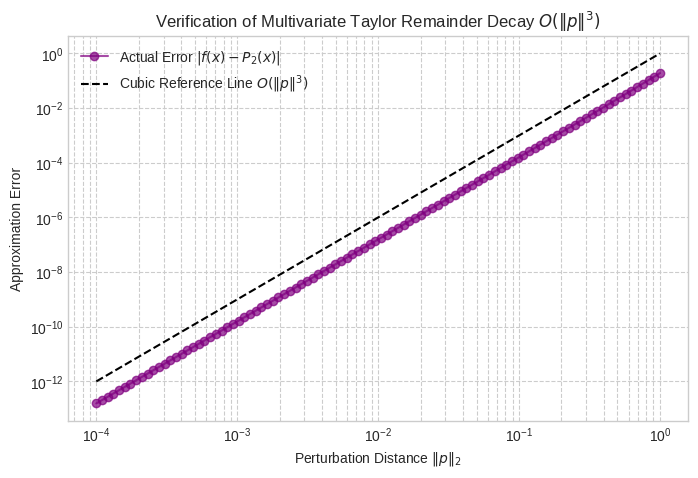

In [ ]:
# NumPy implementations
def f_num(x):
    return x[0]*x[1] + x[0]**2 + np.exp(x[0]) * np.cos(x[1])

def taylor_2nd_num(x):
    return 1.0 + x[0] + 0.5 * (3.0 * x[0]**2 + 2.0 * x[0]*x[1] - x[1]**2)

# Sample along random directions with decreasing norm ||p||
np.random.seed(42)
direction = np.array([0.6, 0.8]) # unit vector
norms = np.logspace(-4, 0, 100)
errors = []

for r in norms:
    p_vec = r * direction
    val_true = f_num(p_vec)
    val_approx = taylor_2nd_num(p_vec)
    errors.append(abs(val_true - val_approx))

plt.figure(figsize=(8, 5))
plt.loglog(norms, errors, 'o-', color='purple', alpha=0.7, label=r'Actual Error $|f(x) - P_2(x)|$')
plt.loglog(norms, norms**3, 'k--', label=r'Cubic Reference Line $O(\|p\|^3)$')

plt.title(r'Verification of Multivariate Taylor Remainder Decay $O(\|p\|^3)$')
plt.xlabel(r'Perturbation Distance $\|p\|_2$')
plt.ylabel('Approximation Error')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

Taylor's Theorem claims for a second order expansion the approximation error $\vert{}f(x) - P_2(x)\vert{}$ decays at a cubic rate $O(\Vert{}p\Vert{}^3)$ as $\Vert{}p\Vert{} \to 0$. We can verify this behavior numerically and show it on the log-log plot above.

# Checklist


*   Read, checked, and personalized each example. Also extended at least one example. They run without errors.
*   Covered key concepts from the textbook and illustrated them in python.
*   Explanations written in my own words accompany each example.
*   Saved directly from collab to github.
*   Carefully formatted, code is explained in comments, and it follows the given order from the textbook and in the canvas assignments